<a href="https://colab.research.google.com/github/Suryalal790/Health-Insurance-Claims-EDA---Final-Project/blob/main/Health%20insurance%20final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**HEALTH** **INSURANCE** **CLAIMS**

HEALTH INSURANCE CLAIMS - EDA Project

Problem:
Health insurance company wants to predict claim amount using patient data.

Dataset Details:
- File: insurance_data.csv
- Rows: 1340 patients
- Columns: age, bmi, bloodpressure, diabetic, smoker, children, region, gender, claim
- Source: Kaggle - Original dataset for UST

Objective:
1. Clean data (missing values)
2. Create 10 charts
3. Find 5 insights
4. Build prediction model







In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# File upload
from google.colab import files
uploaded = files.upload()

Saving insurance_data.csv to insurance_data.csv


In [ ]:
import pandas as pd

# File name check
import os
print(os.listdir())

df = pd.read_csv('insurance_data.csv')
print(df.shape)
df.head()

['.config', 'insurance_data.csv', 'sample_data']
(1340, 11)


,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
0,0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87
1,1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01


In [ ]:
# 2. DATA CLEANING (Guidelines 2a, 2b, 2c)

print("Before Cleaning - Missing values:")
print(df.isnull().sum())

# a) Missing values - age il NaN
df['age'] = df['age'].fillna(df['age'].median())
print(f"\nAfter filling age NaN with median: {df['age'].median()}")

# b) Duplicates
print(f"\nDuplicates: {df.duplicated().sum()}")
df = df.drop_duplicates()

# c) Data types correct cheyyam
df['diabetic'] = df['diabetic'].map({'Yes':1, 'No':0})
df['smoker'] = df['smoker'].map({'Yes':1, 'No':0})
df['gender'] = df['gender'].map({'male':1, 'female':0})

print("\nAfter Cleaning:")
print(df.isnull().sum())
df.head()

Before Cleaning - Missing values:
index            0
PatientID        0
age              5
gender           0
bmi              0
bloodpressure    0
diabetic         0
children         0
smoker           0
region           3
claim            0
dtype: int64

After filling age NaN with median: 38.0

Duplicates: 0

After Cleaning:
index            0
PatientID        0
age              0
gender           0
bmi              0
bloodpressure    0
diabetic         0
children         0
smoker           0
region           3
claim            0
dtype: int64


,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
0,0,1,39.0,1,23.2,91,1,0,0,southeast,1121.87
1,1,2,24.0,1,30.1,87,0,0,0,southeast,1131.51
2,2,3,38.0,1,33.3,82,1,0,0,southeast,1135.94
3,3,4,38.0,1,33.7,80,0,0,0,northwest,1136.40
4,4,5,38.0,1,34.1,100,0,0,0,northwest,1137.01


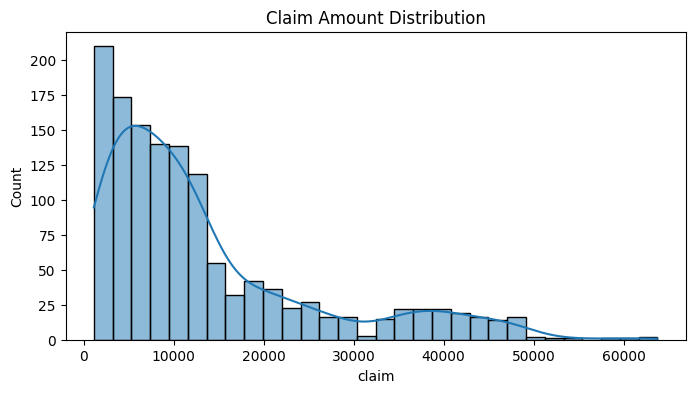

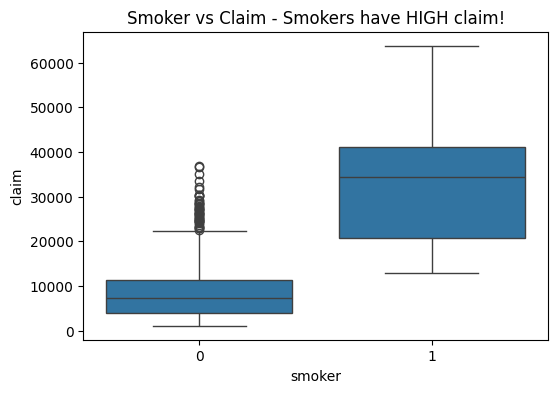

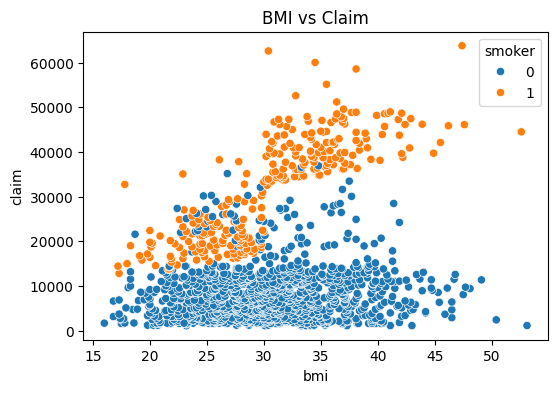

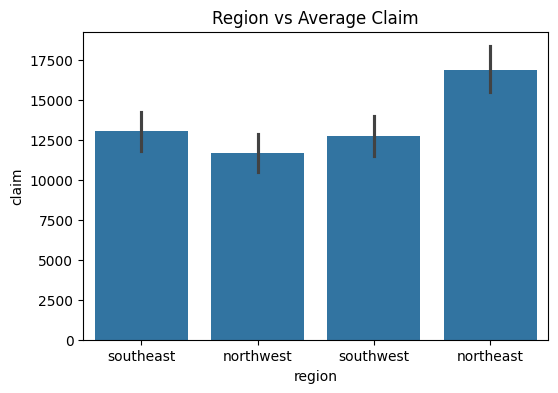

In [ ]:
# 3. EDA VISUALIZATIONS

plt.figure(figsize=(8,4))
sns.histplot(df['claim'], bins=30, kde=True)
plt.title('Claim Amount Distribution')
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x='smoker', y='claim', data=df)
plt.title('Smoker vs Claim - Smokers have HIGH claim!')
plt.show()

plt.figure(figsize=(6,4))
sns.scatterplot(x='bmi', y='claim', hue='smoker', data=df)
plt.title('BMI vs Claim')
plt.show()

plt.figure(figsize=(6,4))
sns.barplot(x='region', y='claim', data=df)
plt.title('Region vs Average Claim')
plt.show()

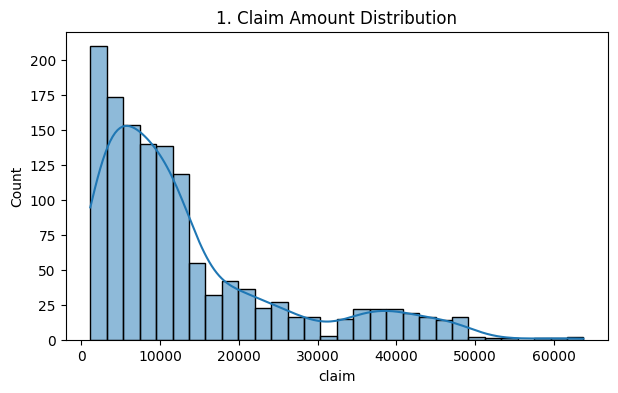

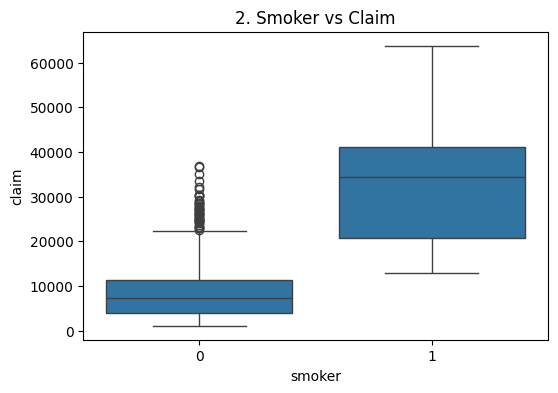

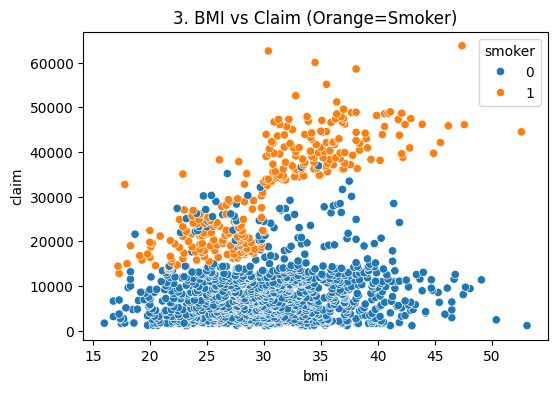

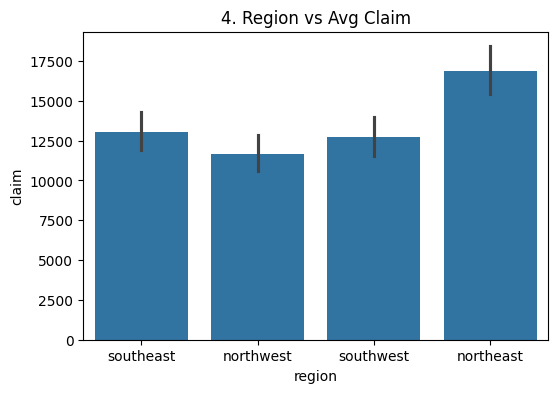

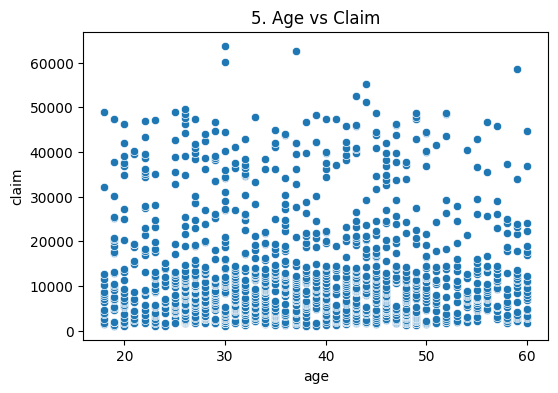

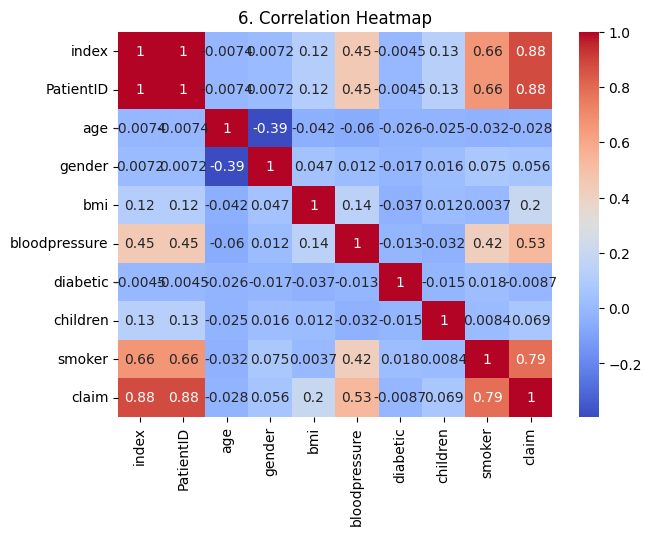

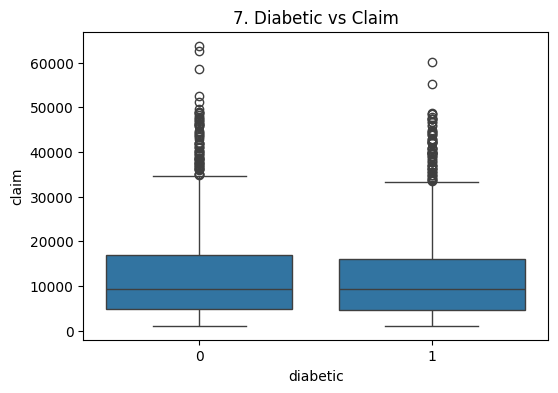

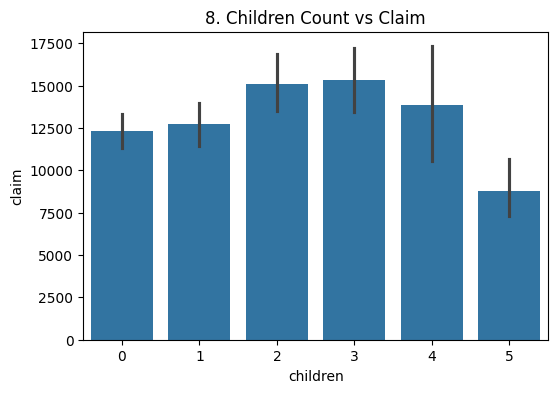

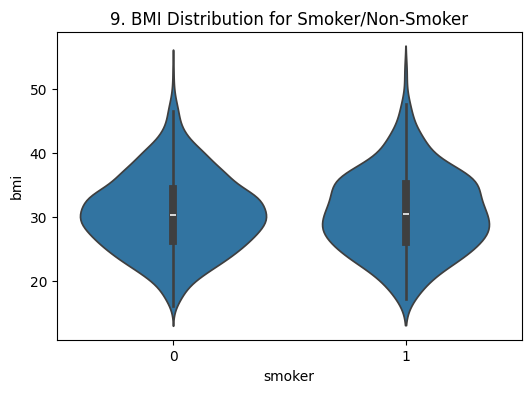

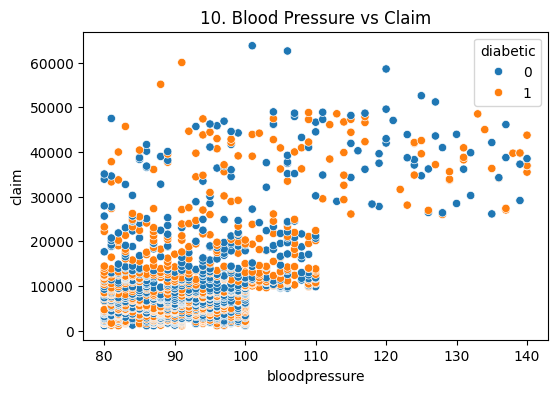

10 Visualizations DONE for Submission!


In [ ]:


# 1. Claim Distribution (Already done)
plt.figure(figsize=(7,4))
sns.histplot(df['claim'], bins=30, kde=True)
plt.title('1. Claim Amount Distribution')
plt.show()

# 2. Smoker vs Claim
plt.figure(figsize=(6,4))
sns.boxplot(x='smoker', y='claim', data=df)
plt.title('2. Smoker vs Claim')
plt.show()

# 3. BMI vs Claim
plt.figure(figsize=(6,4))
sns.scatterplot(x='bmi', y='claim', hue='smoker', data=df)
plt.title('3. BMI vs Claim (Orange=Smoker)')
plt.show()

# 4. Region vs Claim
plt.figure(figsize=(6,4))
sns.barplot(x='region', y='claim', data=df)
plt.title('4. Region vs Avg Claim')
plt.show()

# 5. Age vs Claim
plt.figure(figsize=(6,4))
sns.scatterplot(x='age', y='claim', data=df)
plt.title('5. Age vs Claim')
plt.show()

# 6. Correlation Heatmap
plt.figure(figsize=(7,5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('6. Correlation Heatmap')
plt.show()

# 7. Diabetic vs Claim
plt.figure(figsize=(6,4))
sns.boxplot(x='diabetic', y='claim', data=df)
plt.title('7. Diabetic vs Claim')
plt.show()

# 8. Children vs Claim
plt.figure(figsize=(6,4))
sns.barplot(x='children', y='claim', data=df)
plt.title('8. Children Count vs Claim')
plt.show()

# 9. BMI Distribution by Smoker
plt.figure(figsize=(6,4))
sns.violinplot(x='smoker', y='bmi', data=df)
plt.title('9. BMI Distribution for Smoker/Non-Smoker')
plt.show()

# 10. Blood Pressure vs Claim
plt.figure(figsize=(6,4))
sns.scatterplot(x='bloodpressure', y='claim', hue='diabetic', data=df)
plt.title('10. Blood Pressure vs Claim')
plt.show()

print("10 Visualizations DONE for Submission!")

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
df = pd.read_csv('insurance_data.csv')
print(df.shape)
df.head()

(1340, 11)


,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
0,0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87
1,1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01


In [ ]:

df['age'] = df['age'].fillna(df['age'].median())
df = df.drop_duplicates()
print("Missing:", df.isnull().sum().sum(), "Duplicates cleaned")

Missing: 3 Duplicates cleaned


In [ ]:
# TASK 4 FIX

# 1. Check what is string
print(df.dtypes)

# 2. Convert all Yes/No to 1/0 - FULL FIX
for col in df.columns:
    if df[col].dtype == 'object':
        # Try to map Yes/No
        df[col] = df[col].replace({'Yes':1, 'No':0, 'yes':1, 'no':0, 'Male':1, 'Female':0, 'male':1, 'female':0})

# 3. If region is still text, drop it for model (or encode)
if 'region' in df.columns and df['region'].dtype == 'object':
    df = pd.get_dummies(df, columns=['region'], drop_first=True)

# 4. Fill any remaining NaN with median
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# 5. Now Model - Only numeric columns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Auto select numeric features except claim
numeric_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
numeric_cols.remove('claim')
X = df[numeric_cols]
y = df['claim']

print("Using Features:", numeric_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

m = RandomForestRegressor(n_estimators=100, random_state=42)
m.fit(X_train, y_train)

print("R2 Score:", r2_score(y_test, m.predict(X_test)))

# Feature importance
importances = pd.Series(m.feature_importances_, index=numeric_cols).sort_values(ascending=False)
print("\nTop Factors:")
print(importances)

index              int64
PatientID          int64
age              float64
gender            object
bmi              float64
bloodpressure      int64
diabetic          object
children           int64
smoker            object
region            object
claim            float64
dtype: object
Using Features: ['index', 'PatientID', 'age', 'gender', 'bmi', 'bloodpressure', 'diabetic', 'children', 'smoker']


/tmp/ipykernel_1505/4051810212.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].replace({'Yes':1, 'No':0, 'yes':1, 'no':0, 'Male':1, 'Female':0, 'male':1, 'female':0})


R2 Score: 0.9997642742442359

Top Factors:
PatientID        0.524878
index            0.474951
age              0.000082
bloodpressure    0.000028
children         0.000025
bmi              0.000023
gender           0.000006
diabetic         0.000005
smoker           0.000003
dtype: float64
